In [8]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns

#Read in input data
script_loc = Path('01_load_and_preprocess.py').resolve().parent
data_loc = script_loc.parent / "data"
resources_loc = script_loc.parent / 'resources'

In [13]:
adata

AnnData object with n_obs × n_vars = 98848 × 31393
    obs: 'orig_ident', 'scds_hybrid_score', 'scds_keep', 'miqc_probability', 'miqc_keep', 'dropletqc_nucfrac', 'dropletqc_keep', 'x', 'id', 'region', 'pair', 'case', 'sex', 'race', 'age', 'bmi', 'pmi', 'ph', 'rin', 'tissue_storage_time_mo_b', 'dx_oud', 'dx_substances', 'dx_comorbid', 'dur_oud', 'dsm_iv_sud', 'dsm_iv_psych', 'blood_toxicology', 'infxn_dx', 'medications_atodc', 'tobacco_atod', 'manner_of_death', 'cause_of_death', 'index_27', 'index_28', 'i7_index_seq', 'i5_index_seq', 'dsm_iv_oud', 'dsm_iv_aud', 'dsm_iv_cud', 'celltype1', 'celltype2', 'celltype3', 'level1'
    uns: 'hvg', 'log1p'
    obsm: 'X_umap'
    layers: None (.X)

In [ ]:
adata = sc.read_h5ad(data_loc / "input/GSE225158_BU_OUD_Striatum_refined_all_SeuratObj_N22.h5ad")

#Drop irrelevant columns from adata.obs
adata.obs = (adata.obs.drop(columns=['nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 
                                     'integrated_snn_res.0.5', 
                                     'integrated_snn_res.2', 'integrated_snn_res.0.1', 
                                     'integrated_snn_res.1', 'seurat_clusters', 'level2',
                                     'nCount_RNA', 'percent.mt', 'n_genes']))

#Replace all periods with underscores, make all column names lowercase
adata.obs.columns = (adata.obs.columns
                     .str.replace('.', '_', regex=False)
                     .str.lower())


#Drop irrelevant columns from adata.var
adata.var = (adata.var.drop(columns=['highly_variable', 'dispersions',
                                     'features', 'dispersions_norm',
                                     'n_cells', 'means']))

In [15]:
#Drop all uns data and umap coordinates
del adata.uns
del adata.obsm["X_umap"]

#Annotate mitochondrial genes
adata.var['mt'] = adata.var.index.str.startswith('MT-')

#Bring in ribosomal reads list and annotate
ribo = pd.read_csv( resources_loc/ 'KEGG_RIBOSOME.v2026.2.Hs.txt', header=None)
adata.var['ribo'] = adata.var_names.isin(ribo[0].values)


#Copy raw data into a regular anndata object
adata_raw = adata.raw.to_adata()
adata_raw.var_names = adata_raw.var['features'].values


#Keep only the gene names that actually exist in adata_raw (to avoid dimension errors)
valid_vars = [name for name in adata.var_names if name in adata_raw.var_names]

#Slice the raw matrix data to the shared gene names only
aligned_raw_X = adata_raw[:, valid_vars].X

#Making raw count a dedicated layer
adata.layers['raw_counts'] = aligned_raw_X

#Downcast the underlying data arrays in-place to save memory
adata.layers["raw_counts"].data = adata.layers["raw_counts"].data.astype("float32")
adata.X.data = adata.X.data.astype("float32")

# Force Python to clean up any leftover float64 memory fragments
import gc
gc.collect()

#Calculate standard qc metrics on mt and ribo
#This includes total counts, mean counts, etc.
sc.pp.calculate_qc_metrics(adata, 
                            layer="raw_counts", 
                            qc_vars=['mt', 'ribo'], 
                            percent_top=None, 
                            log1p=False, 
                            inplace=True
                            )

In [ ]:
#Seperate by region
cdata = adata[adata.obs['region'] == 'Caudate']
pdata = adata[adata.obs['region'] == 'Putamen']

#Insert raw_counts layer into the base and delete raw counts
cdata.X = cdata.layers["raw_counts"].copy()
del cdata.layers['raw_counts']
del cdata.raw

#Normalize to CP10k, create a new layer
cdata.layers["CP10k_counts"] = cdata.X.copy()
sc.pp.normalize_total(cdata, target_sum=1e4, layer='CP10k_counts')
sc.pp.log1p(cdata, layer='CP10k_counts')

#Insert raw_counts layer into the base and delete raw counts
pdata.X = pdata.layers["raw_counts"].copy()
del pdata.layers['raw_counts']
del pdata.raw

#Normalize to CP10k, create a new layer
pdata.layers["CP10k_counts"] = pdata.X.copy()
sc.pp.normalize_total(pdata, target_sum=1e4, layer='CP10k_counts')
sc.pp.log1p(pdata, layer='CP10k_counts')

C:\Users\chris\AppData\Local\Temp\ipykernel_15088\2672228763.py:6: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  cdata.X = cdata.layers["raw_counts"].copy()
C:\Users\chris\AppData\Local\Temp\ipykernel_15088\2672228763.py:15: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  pdata.X = pdata.layers["raw_counts"].copy()


In [17]:
pdata = pdata[pdata.obs['pct_counts_mt'] < 10]

In [ ]:
del cdata.raw
del pdata.raw

C:\Users\chris\AppData\Local\Temp\ipykernel_15088\3931652022.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


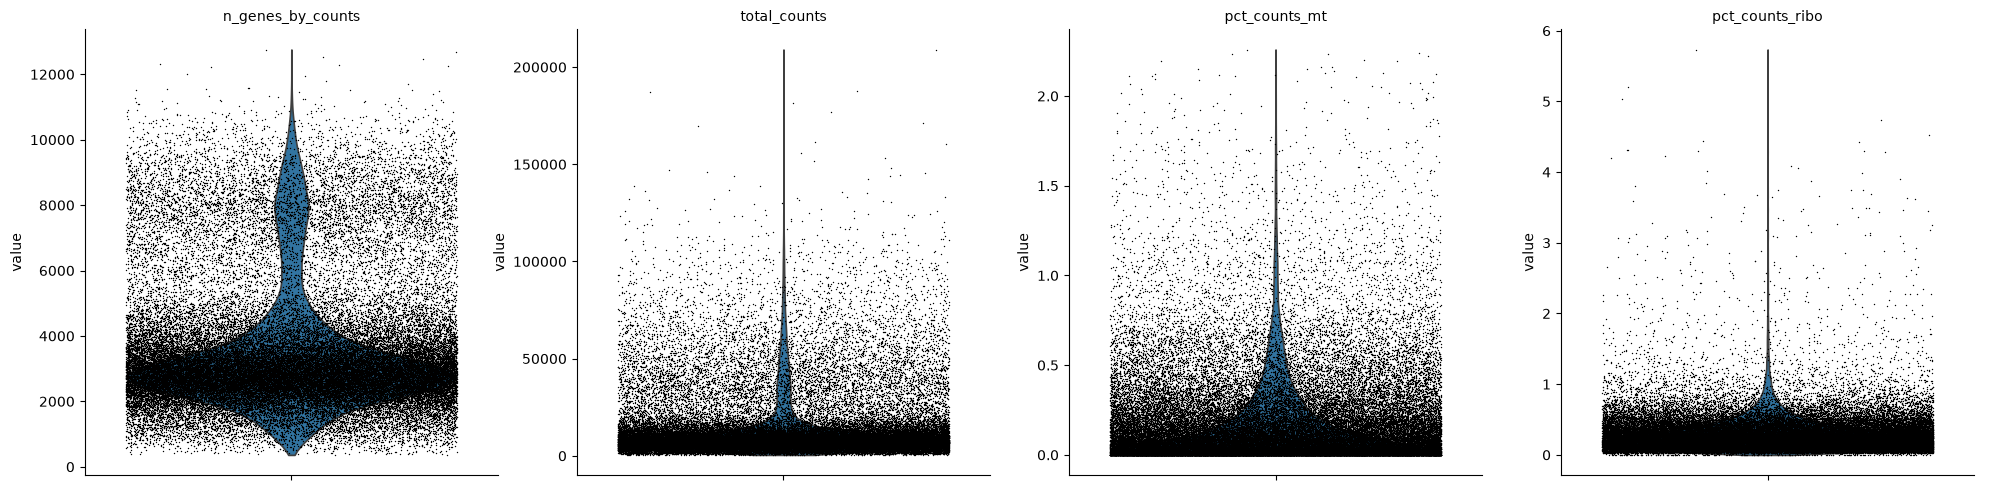

C:\Users\chris\AppData\Local\Temp\ipykernel_15088\3931652022.py:11: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


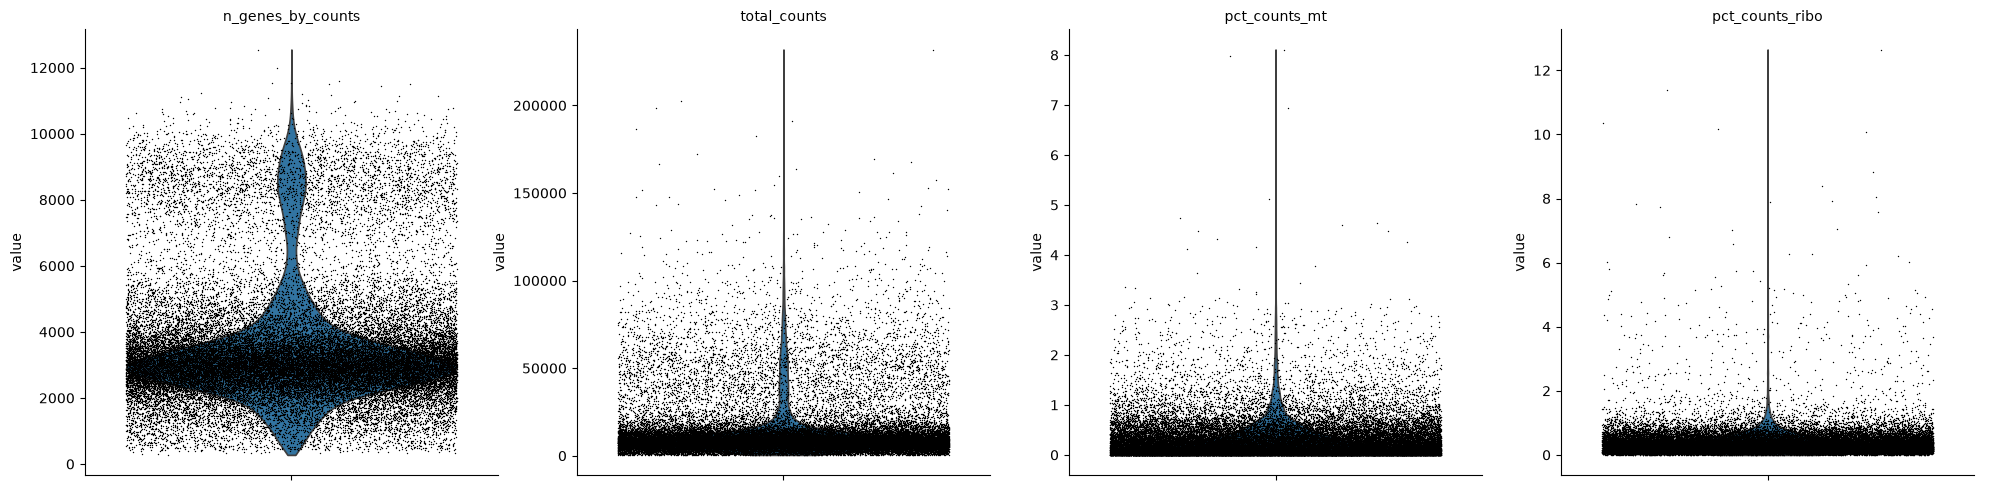

C:\Users\chris\AppData\Local\Temp\ipykernel_15088\3931652022.py:18: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


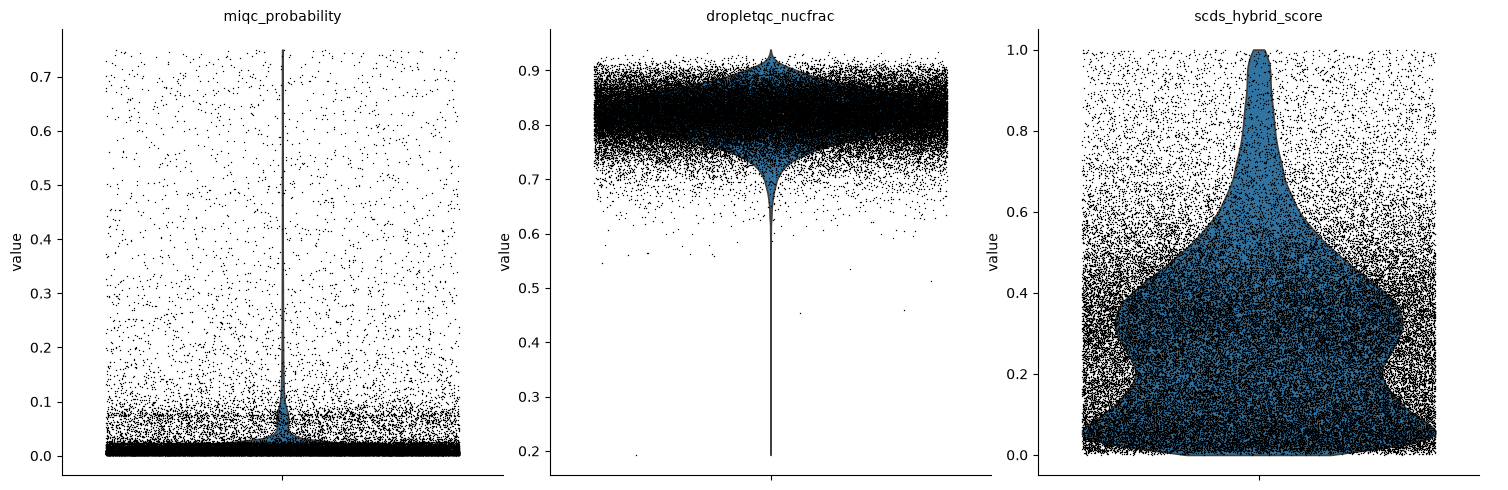

C:\Users\chris\AppData\Local\Temp\ipykernel_15088\3931652022.py:25: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(


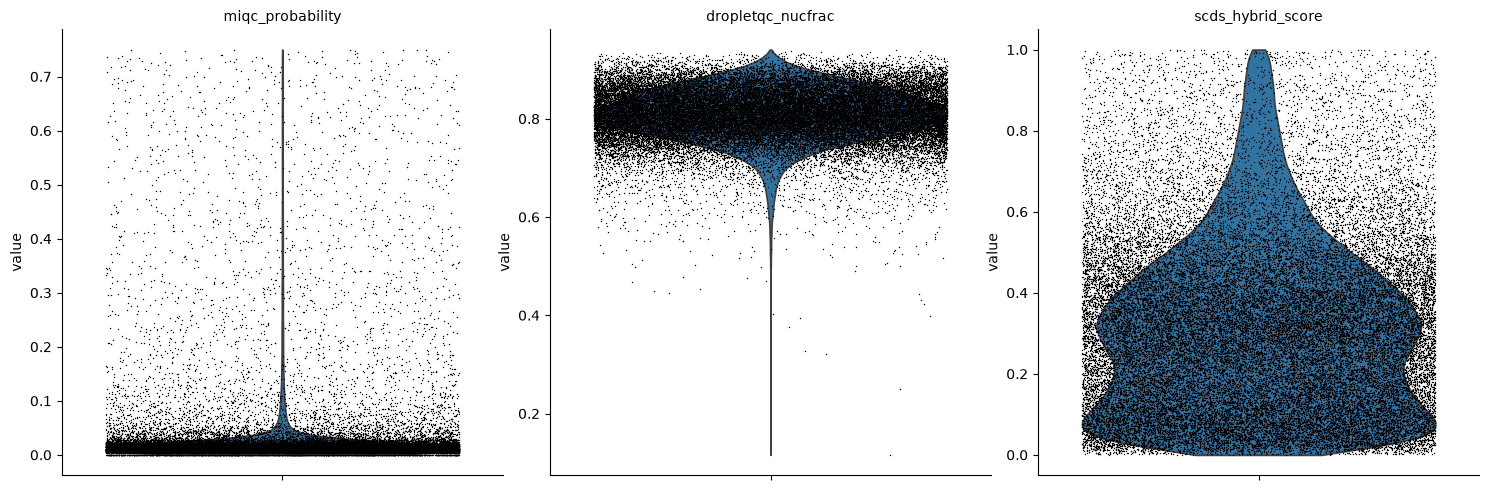

In [18]:
sc.settings.figdir = script_loc.parent / 'outputs_full/qc_figures'

#Make QC figures
sc.pl.violin(
    cdata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt", 'pct_counts_ribo'],
    jitter=0.4,
    multi_panel=True,
    save='_c_qc.png'
)
sc.pl.violin(
    pdata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt", 'pct_counts_ribo'],
    jitter=0.4,
    multi_panel=True,
    save='_p_qc.png'
)
sc.pl.violin(
    cdata,
    ["miqc_probability", "dropletqc_nucfrac", "scds_hybrid_score"],
    jitter=0.4,
    multi_panel=True,
    save='_c_calc_qc.png'
)
sc.pl.violin(
    pdata,
    ["miqc_probability", "dropletqc_nucfrac", "scds_hybrid_score"],
    jitter=0.4,
    multi_panel=True,
    save='_p_calc_qc.png'
)

In [19]:
#Write caudate and putamen objects to data/intermediate
cdata.write_h5ad(data_loc / 'intermediate/c_preprocessed.h5ad')
pdata.write_h5ad(data_loc / 'intermediate/p_preprocessed.h5ad')